
# Lab 7: Fast Fourier Transform (FFT)

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


 **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.


In [3]:
import numpy as np                 # arreglos y operaciones numéricas
import matplotlib.pyplot as plt    # gráficas
from scipy import fft              # FFT de scipy (fft, fft2, ifft2, fftshift)
from PIL import Image              # solo para abrir y redimensionar la imagen

In [12]:
# Parámetros

RUTA_IMAGEN = 'guacamaya.jpg'

# Tamaño al que reducimos la imagen. Se reduce porque la rutina
# de clase hace bucles en Python: con 128x128 tarda un par de segundos
N_PIXELES = 128

# Tolerancia para decir "dan lo mismo"
TOL = 1e-6

Forma de la imagen: (128, 128)


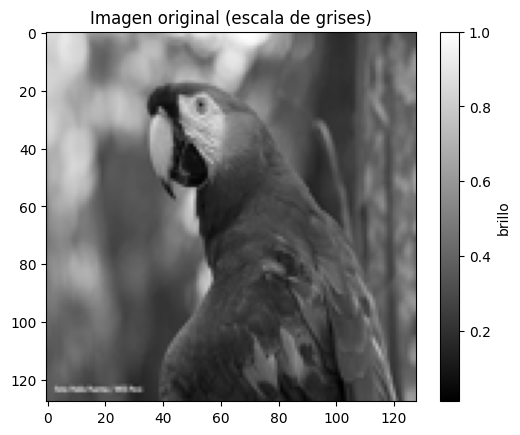

In [13]:
# Cargamos la imagen

def cargar_imagen(ruta,n):
    img = Image.open(ruta)
    img = img.convert('L')
    img = img.resize ((n,n))
    # Pasar a arreglo de numpy con valores entre 0 y 1
    return np.array(img, dtype=float) / 255.0

imagen = cargar_imagen(RUTA_IMAGEN, N_PIXELES)
print('Forma de la imagen:', imagen.shape)

plt.imshow(imagen, cmap='gray')
plt.title('Imagen original (escala de grises)')
plt.colorbar(label='brillo')
plt.show()


**FFT 2D con scipy**

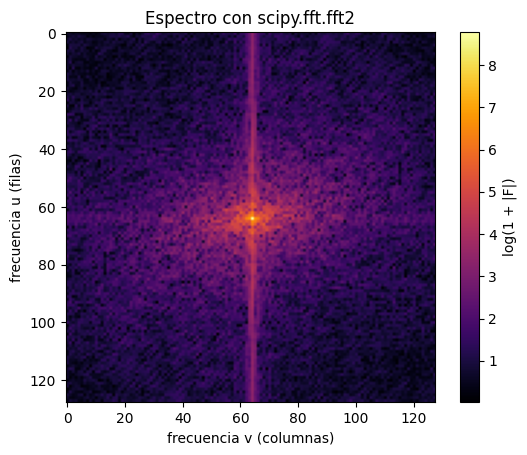

In [14]:
F_scipy = fft.fft2(imagen)    # transformada 2D: arreglo complejo del mismo tamaño que la imagen

def graficar_espectro(F, titulo):
    espectro = np.log(1 + np.abs(F))   # magnitud en escala logarítmica
    espectro = fft.fftshift(espectro)  # frecuencia (0,0) al centro de la gráfica
    plt.imshow(espectro, cmap='inferno')
    plt.title(titulo)
    plt.xlabel('frecuencia v (columnas)')
    plt.ylabel('frecuencia u (filas)')
    plt.colorbar(label='log(1 + |F|)')
    plt.show()

graficar_espectro(F_scipy, 'Espectro con scipy.fft.fft2')

**Rutina de clase FT(x,y) modificada**

La rutina de clase calcula, para cada frecuencia w, la integral $$\tilde f(w)=\int f(t)\,e^{-i2\pi w t}\,dt$$ separando parte real e imaginaria con `integrate.quad`. Para una imagen hay que cambiar lo siguiente:

- Los datos son píxeles discretos (no una función continua), así que la integral se aproxima por una suma sobre los puntos  $\int f(t)e^{-i2\pi wt}dt \approx \sum_n f(t_n)e^{-i2\pi w t_n}\Delta t$, con $t_n=n$ y $\Delta t=1$ píxel.

- En lugar de `w = np.linspace(0.1, 1, 100)` usaremos las mismas frecuencias que la FFT: $w_k=k/N$, con $k=0,1,...,N-1$. Si no, no podríamos comparar punto a punto. 


**En 2D:** La exponencial se factoriza: $e^{i2\pi(ux/N_x + vy/N_y)}=e^{-i2\pi ux/N_x} e^{-i2\pi vy/N_y}$. Entonces la transformada 2D es igual a aplicar la 1D a cada fila y luego a cada columna del resultado. Así reutilizamos la rutina 1D de clase


In [15]:
def g(t, w):
    return np.exp(-1j*2*np.pi*w*t)

def FT_1D(y):
    N = len(y)
    t = np.arange(N)         # posiciones de las muestras: 0, 1, ..., N-1
    w = np.arange(N) / N     # frecuencias w_k = k/N
    resultado = np.zeros(N, dtype=complex)

    for i in range(N):
        # En clase: integrate.quad(...). Aquí suma sobre los puntos
        AReW = np.sum(y * g(t, w[i]).real)
        AImW = np.sum(y * g(t, w[i]).imag)
        resultado[i] = AReW +1j * AImW
    return resultado

def FT_2D(imagen):
    #Transformada aplicando FT_1D primero a cada fila y luego a cada columna
    filas, columnas = imagen.shape
    paso1 = np.zeros((filas, columnas), dtype=complex)
    paso2 = np.zeros((filas, columnas), dtype=complex)

    # Transformar cada fila (recorre la dirección y)
    for r in range(filas):
        paso1[r, :] = FT_1D(imagen[r, :])

    # Transformar cada columna del resultado anterior (recorre la dirección x)
    for c in range(columnas):
        paso2[:, c] = FT_1D(paso1[:, c])
    return paso2

**Transformada de la imagen con la rutina modificada y comparación**

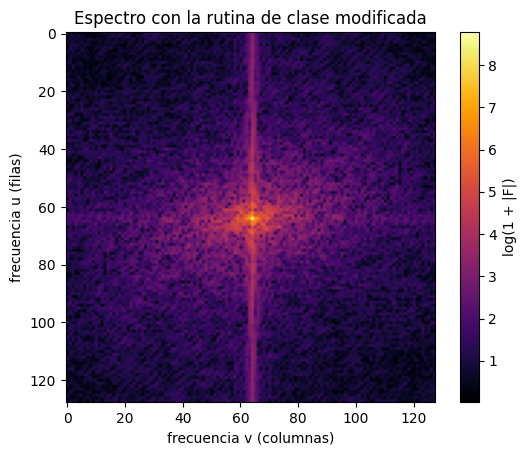

Diferencia máxima |F_manual - F_scipy|: 3.0277459098296655e-11
Valor típico de |F_scipy|            : 7.1031039442462145
¿Iguales dentro de la tolerancia?     : True


In [16]:
F_manual = FT_2D(imagen)

graficar_espectro(F_manual, 'Espectro con la rutina de clase modificada')

# Comparación numérica: diferencia en cada frecuencia
diferencia = np.abs(F_manual - F_scipy)
print('Diferencia máxima |F_manual - F_scipy|:', diferencia.max())
print('Valor típico de |F_scipy|            :', np.abs(F_scipy).mean())
print('¿Iguales dentro de la tolerancia?     :', diferencia.max() < TOL)

**FFT inversa y reconstrucción**

La transformada inversa es

$$f(x,y)=\frac{1}{N_xN_y}\sum_{u}\sum_{v}F(u,v)\,e^{+i2\pi\left(\frac{u\,x}{N_x}+\frac{v\,y}{N_y}\right)}$$

Error máximo (scipy) : 5.551115123125783e-16
Error máximo (rutina de clase): 1.9984014443252818e-14


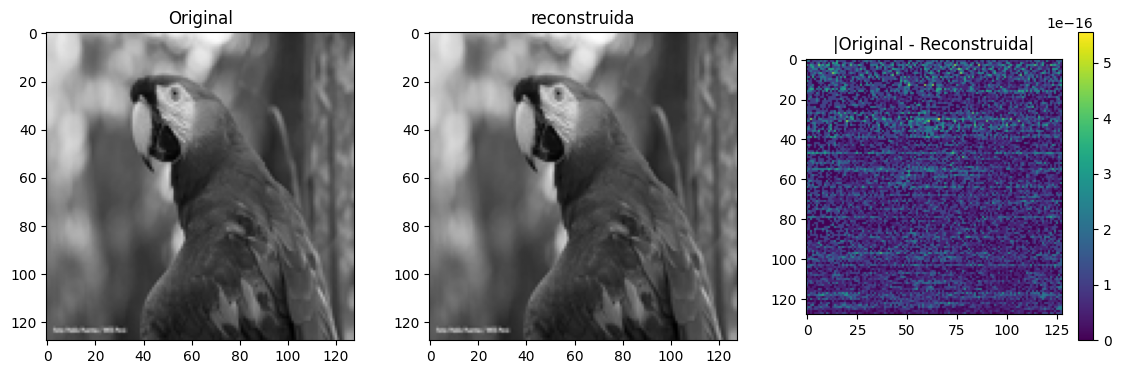

In [17]:
reconstruida = fft.ifft2(F_scipy).real              # inversa de la FFT de scipy
reconstruida_manual = fft.ifft2(F_manual).real      # inversa de nuestra transformada

error = np.abs(imagen - reconstruida)
print('Error máximo (scipy) :', error.max())
print('Error máximo (rutina de clase):', np.abs(imagen - reconstruida_manual).max())

# Comparación visual: original, reconstruida y diferencia
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
ejes[0].imshow(imagen, cmap='gray'); ejes[0].set_title('Original')
ejes[1].imshow(reconstruida, cmap='gray'); ejes[1].set_title('reconstruida')
im = ejes[2].imshow(error, cmap='viridis'); ejes[2].set_title('|Original - Reconstruida|')
fig.colorbar(im, ax=ejes[2])
plt.show()


La reconstruida es indistinguible de la original y el mapa de diferencias sólo muestra valores del orden de $10^{-16}$ (precisión de máquina). Esto pasa porque la transformada de Fourier discreta es invertible: no se pierde información al ir al espacio de frecuencias y volver. Lo mismo ocurre partiendo de la transformada calculada con la rutina de clase.